# PBL Fase 6 — Visão Computacional com YOLO

**Aluno:** Nelson Henry Campos — **RM:** 573230

Objetivo: detectar e classificar **2 objetos visualmente distintos** — **violão/guitarra (`guitar`)** e **bule/chaleira (`teapot`)** — comparando três abordagens:

1. **YOLO customizado** (fine-tuning do YOLO11n no nosso dataset), treinado 2 vezes com números de épocas diferentes (30 e 60);
2. **YOLO padrão** (pré-treinado no COCO, sem treino customizado);
3. **CNN treinada do zero** (PyTorch) para classificação das 2 classes.

**Dataset:** 40 imagens por objeto (80 no total), separadas por objeto em **32 treino / 4 validação / 4 teste** → 64 / 8 / 8.
Imagens do [Open Images V7](https://storage.googleapis.com/openimages/web/index.html) (licença CC BY 2.0, créditos em `dataset/CREDITS.csv`), curadas manualmente (removidos jarros, prensas francesas, cafeteiras, banjos, bandolins, violinos e imagens muito pequenas/escuras).
As imagens de treino e validação foram **rotuladas no [Make Sense](https://www.makesense.ai)** e exportadas no formato YOLO (`dataset/makesense_export_yolo.zip`). As caixas foram desenhadas no Make Sense com automação de navegador, usando como referência as coordenadas das anotações do Open Images, e o export foi conferido arquivo a arquivo (1 caixa por imagem, classe correta).

Estrutura no Google Drive:
```
MyDrive/pbl_fase6/dataset/
├── data.yaml
├── train/{images,labels}   # 64 imagens
├── val/{images,labels}     # 8 imagens
└── test/{images,labels}    # 8 imagens (sem rótulo — usadas só para inferência)
```

## a) Montar o Google Drive e instalar o Ultralytics

No Colab, o Drive é montado em `/content/drive` e o dataset é lido de `MyDrive/pbl_fase6/dataset`. Os resultados dos treinos (`runs/`) também ficam no Drive, para não se perderem caso a sessão do Colab caia.
Fora do Colab (execução local), a célula usa a pasta `dataset/` ao lado do notebook.

O dispositivo é escolhido automaticamente (GPU CUDA no Colab, `mps` em Mac Apple Silicon, ou CPU). **Todas as medições de tempo deste notebook são feitas no mesmo dispositivo**, para que a comparação entre abordagens seja justa.

In [1]:
import os, sys, subprocess

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics'], check=True)
    BASE = '/content/drive/MyDrive/pbl_fase6'
else:
    BASE = os.path.abspath('.')

DATASET = os.path.join(BASE, 'dataset')
RUNS = os.path.join(BASE, 'runs')
os.makedirs(RUNS, exist_ok=True)

import torch, ultralytics
DEVICE = 0 if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
TORCH_DEVICE = torch.device('cuda' if DEVICE == 0 else DEVICE)
print('Colab:', IN_COLAB, '| ultralytics', ultralytics.__version__, '| torch', torch.__version__, '| device:', DEVICE)
for split in ('train', 'val', 'test'):
    imgs = os.listdir(os.path.join(DATASET, split, 'images'))
    lbls = [f for f in os.listdir(os.path.join(DATASET, split, 'labels')) if f.endswith('.txt')]
    print(f'{split:5s}: {len(imgs)} imagens, {len(lbls)} rótulos')

Colab: False | ultralytics 8.4.177 | torch 2.14.1 | device: mps
train: 64 imagens, 64 rótulos
val  : 8 imagens, 8 rótulos
test : 8 imagens, 0 rótulos


### data.yaml

O `data.yaml` exportado junto com o dataset define as 2 classes, na mesma ordem usada no Make Sense (`0: guitar`, `1: teapot`).
Como o caminho absoluto muda entre Colab e máquina local, geramos uma cópia com `path` apontando para o diretório real.

In [2]:
import yaml
with open(os.path.join(DATASET, 'data.yaml')) as f:
    data_cfg = yaml.safe_load(f)
data_cfg['path'] = DATASET
DATA_YAML = os.path.join(RUNS, 'data_runtime.yaml')
with open(DATA_YAML, 'w') as f:
    yaml.safe_dump(data_cfg, f, sort_keys=False)
CLASSES = [data_cfg['names'][i] for i in range(data_cfg['nc'])]
print(open(DATA_YAML).read())

path: /Users/nelsoncampos/dev/college/fiap-pbl-fase6-yolo/dataset
train: train/images
val: val/images
test: test/images
nc: 2
names:
  0: guitar
  1: teapot



## b) Treinar o YOLO customizado — 30 vs 60 épocas

Partimos do **YOLO11n** pré-treinado (transfer learning) e fazemos fine-tuning com nossas 2 classes.
Mesmos hiperparâmetros nos dois treinos (`imgsz=640`, `batch=16`, `seed=0`); só muda o número de épocas.
O tempo de treino é medido com relógio de parede, depois de um treino curto de aquecimento que não entra na conta.

In [3]:
import time
from ultralytics import YOLO

def train_yolo(epochs):
    model = YOLO('yolo11n.pt')
    t0 = time.perf_counter()
    model.train(data=DATA_YAML, epochs=epochs, imgsz=640, batch=16, seed=0, deterministic=True,
                device=DEVICE, project=RUNS, name=f'yolo_{epochs}ep', exist_ok=True, plots=True, verbose=False)
    return time.perf_counter() - t0

# aquecimento (não cronometrado): a 1ª execução compila kernels da GPU e cria o cache dos rótulos,
# o que inflaria o tempo do primeiro treino e distorceria a comparação 30 x 60 épocas
YOLO('yolo11n.pt').train(data=DATA_YAML, epochs=1, imgsz=640, batch=16, device=DEVICE, project=RUNS,
                         name='warmup', exist_ok=True, plots=False, val=False, verbose=False)

train_time = {}
for ep in (30, 60):
    train_time[ep] = train_yolo(ep)
    print(f'>>> {ep} épocas: {train_time[ep]/60:.1f} min')

Ultralytics 8.4.177 🚀 Python-3.12.2 torch-2.14.1 MPS (Apple M4 Max)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/nelsoncampos/dev/college/fiap-pbl-fase6-yolo/runs/data_runtime.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=warmup, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=

Overriding model.yaml nc=80 with nc=2



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.7it/s 0.2s

                   all          8          8      0.636      0.861      0.847      0.488


Speed: 0.1ms preprocess, 15.1ms inference, 0.0ms loss, 1.0ms postprocess per image


Results saved to /Users/nelsoncampos/dev/college/fiap-pbl-fase6-yolo/runs/yolo_60ep


>>> 60 épocas: 2.9 min


### Comparação das métricas (conjunto de validação)

- **Precisão / Recall / mAP50 / mAP50-95**: avaliação do melhor checkpoint (`best.pt`) de cada treino no conjunto de validação.
- **Perdas**: valores da última época (`results.csv`) para treino e validação (box, cls, dfl).

In [4]:
import pandas as pd

rows, curves = [], {}
for ep in (30, 60):
    run_dir = os.path.join(RUNS, f'yolo_{ep}ep')
    m = YOLO(os.path.join(run_dir, 'weights', 'best.pt')).val(data=DATA_YAML, split='val', device=DEVICE,
                                                               project=RUNS, name=f'val_{ep}ep', exist_ok=True, verbose=False)
    csv = pd.read_csv(os.path.join(run_dir, 'results.csv'))
    csv.columns = [c.strip() for c in csv.columns]
    curves[ep] = csv
    last = csv.iloc[-1]
    rows.append({
        'épocas': ep,
        'precisão': m.box.mp, 'recall': m.box.mr, 'mAP50': m.box.map50, 'mAP50-95': m.box.map,
        'train box_loss': last['train/box_loss'], 'train cls_loss': last['train/cls_loss'], 'train dfl_loss': last['train/dfl_loss'],
        'val box_loss': last['val/box_loss'], 'val cls_loss': last['val/cls_loss'], 'val dfl_loss': last['val/dfl_loss'],
        'tempo de treino (min)': train_time[ep] / 60,
    })
yolo_cmp = pd.DataFrame(rows).set_index('épocas')
yolo_cmp.round(3)

Ultralytics 8.4.177 🚀 Python-3.12.2 torch-2.14.1 MPS (Apple M4 Max)


YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1670.7±210.5 MB/s, size: 167.6 KB)


val: Scanning /Users/nelsoncampos/dev/college/fiap-pbl-fase6-yolo/dataset/val/labels.cache... 8 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 8/8 6.7Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 5.5it/s 0.2s

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 14.1it/s 0.1s

                   all          8          8      0.636      0.861      0.847      0.488


Speed: 0.2ms preprocess, 2.9ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to /Users/nelsoncampos/dev/college/fiap-pbl-fase6-yolo/runs/val_60ep


,precisão,recall,mAP50,mAP50-95,train box_loss,train cls_loss,train dfl_loss,val box_loss,val cls_loss,val dfl_loss,tempo de treino (min)
épocas,,,,,,,,,,,
30,0.902,0.690,0.779,0.574,0.513,0.663,1.161,1.344,1.571,2.393,1.414
60,0.636,0.861,0.847,0.488,0.430,0.451,1.091,1.608,1.021,2.613,2.861


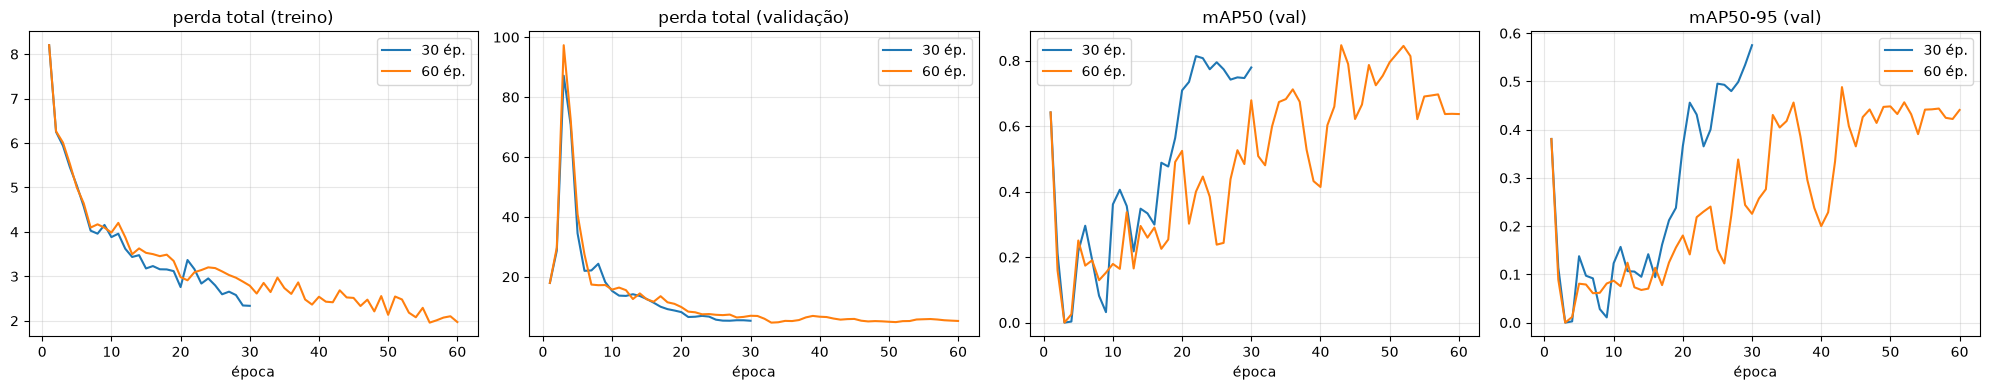

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ep, c in curves.items():
    axes[0].plot(c['epoch'], c['train/box_loss'] + c['train/cls_loss'] + c['train/dfl_loss'], label=f'{ep} ép.')
    axes[1].plot(c['epoch'], c['val/box_loss'] + c['val/cls_loss'] + c['val/dfl_loss'], label=f'{ep} ép.')
    axes[2].plot(c['epoch'], c['metrics/mAP50(B)'], label=f'{ep} ép.')
    axes[3].plot(c['epoch'], c['metrics/mAP50-95(B)'], label=f'{ep} ép.')
for ax, t in zip(axes, ['perda total (treino)', 'perda total (validação)', 'mAP50 (val)', 'mAP50-95 (val)']):
    ax.set_title(t); ax.set_xlabel('época'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## c) Detecções nas imagens de teste (YOLO customizado)

Usamos o modelo de 60 épocas nas 8 imagens de teste, que o modelo nunca viu.
O teste não tem rótulos de caixa (só treino e validação foram rotulados). Por isso medimos o **acerto por imagem**: a detecção de maior confiança precisa ter a classe certa, e a classe verdadeira vem do nome do arquivo.

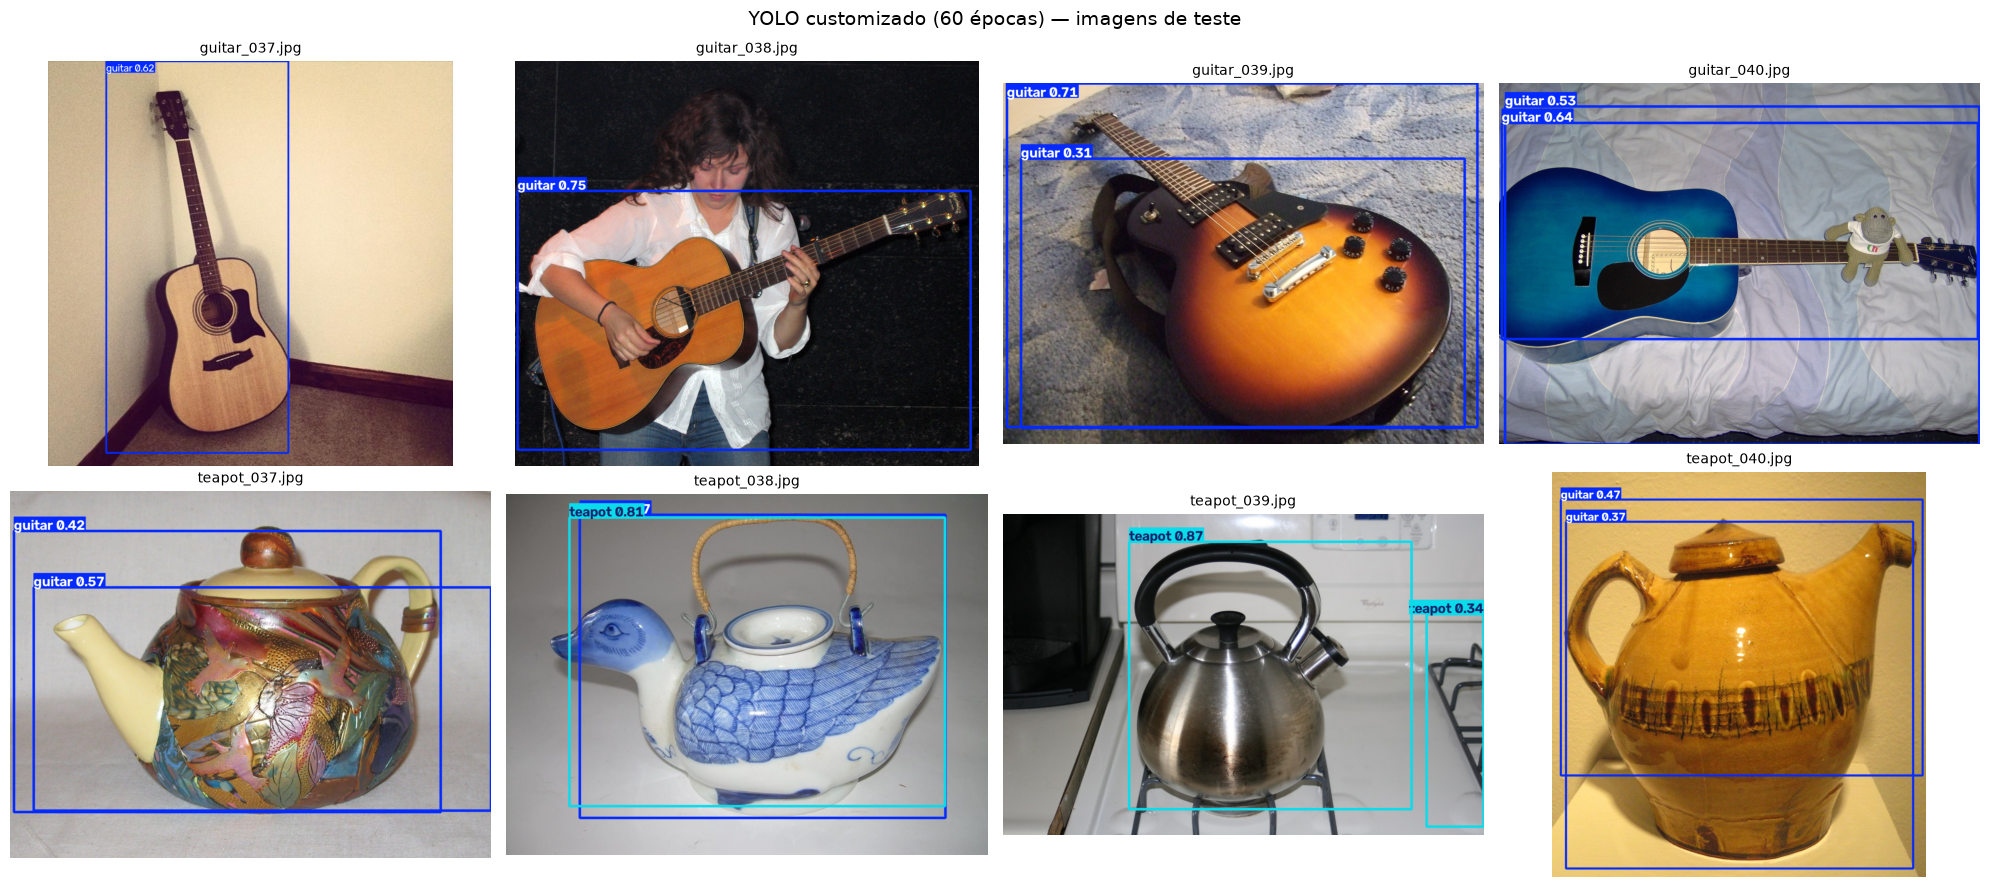

Acerto por imagem (teste): 75%


,imagem,classe real,predição (top),confiança,nº caixas,acerto
0,guitar_037.jpg,guitar,guitar,0.618,1,True
1,guitar_038.jpg,guitar,guitar,0.752,1,True
2,guitar_039.jpg,guitar,guitar,0.714,2,True
3,guitar_040.jpg,guitar,guitar,0.637,2,True
4,teapot_037.jpg,teapot,guitar,0.573,2,False
5,teapot_038.jpg,teapot,teapot,0.810,2,True
6,teapot_039.jpg,teapot,teapot,0.872,2,True
7,teapot_040.jpg,teapot,guitar,0.466,2,False


In [6]:
import glob
from PIL import Image

TEST_IMGS = sorted(glob.glob(os.path.join(DATASET, 'test', 'images', '*.jpg')))
true_cls = lambda p: os.path.basename(p).split('_')[0]

custom = YOLO(os.path.join(RUNS, 'yolo_60ep', 'weights', 'best.pt'))

def show_grid(results, title):
    fig, axes = plt.subplots(2, 4, figsize=(20, 9))
    for ax, r in zip(axes.flat, results):
        ax.imshow(r.plot()[..., ::-1]); ax.axis('off'); ax.set_title(os.path.basename(r.path), fontsize=10)
    fig.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

def top_label(r):
    if len(r.boxes) == 0:
        return None, 0.0
    i = int(r.boxes.conf.argmax())
    return r.names[int(r.boxes.cls[i])], float(r.boxes.conf[i])

res_custom = custom.predict(TEST_IMGS, conf=0.25, device=DEVICE, verbose=False)
show_grid(res_custom, 'YOLO customizado (60 épocas) — imagens de teste')
det_custom = pd.DataFrame([{'imagem': os.path.basename(r.path), 'classe real': true_cls(r.path),
                            'predição (top)': top_label(r)[0], 'confiança': round(top_label(r)[1], 3),
                            'nº caixas': len(r.boxes)} for r in res_custom])
det_custom['acerto'] = det_custom['classe real'] == det_custom['predição (top)']
acc_custom = det_custom['acerto'].mean()
print(f'Acerto por imagem (teste): {acc_custom:.0%}')
det_custom

## d) Comparação com o YOLO padrão (pré-treinado no COCO)

Rodamos o mesmo **YOLO11n**, sem treino customizado, nas mesmas imagens de teste.
O COCO tem 80 classes, mas **não tem `guitar` nem `teapot`**. O modelo padrão não consegue nomear nossos objetos e, no máximo, acerta uma classe "vizinha" (`vase`, `cup`, `bottle`…) ou detecta só a pessoa que toca o instrumento.

guitar no COCO? False | teapot no COCO? False


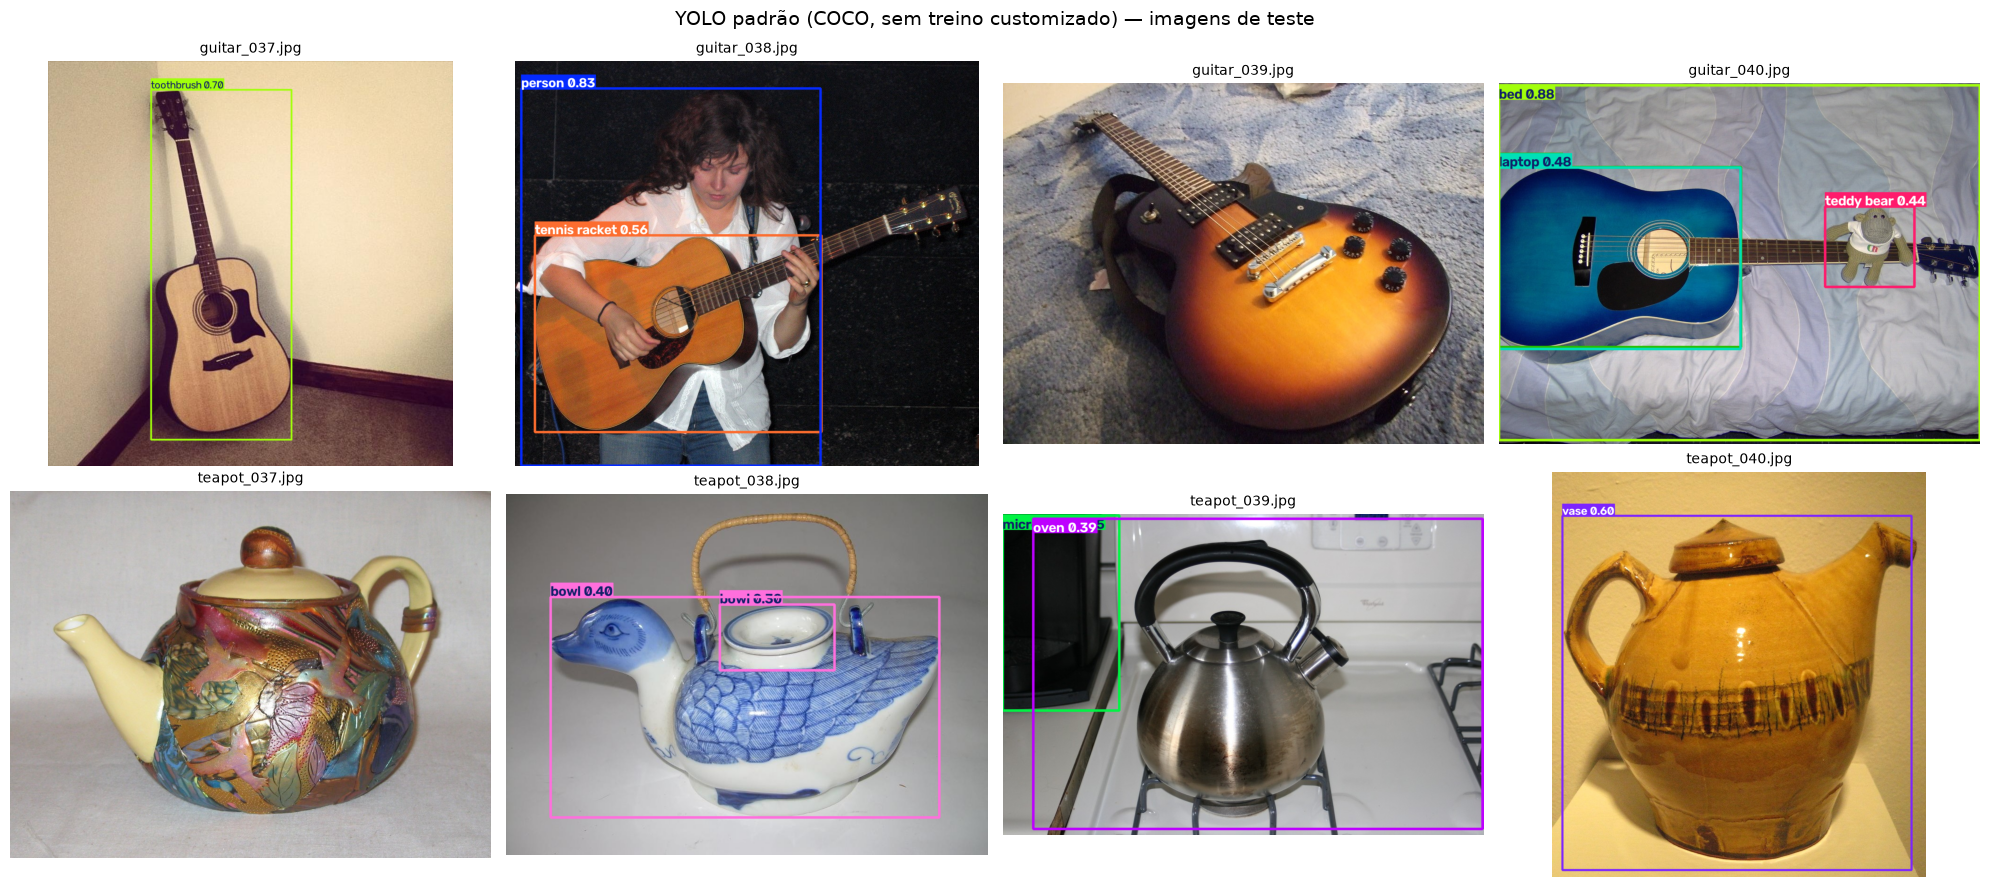

Acerto por imagem (teste): 0%


,imagem,classe real,classes detectadas,predição (top),acerto
0,guitar_037.jpg,guitar,toothbrush,toothbrush,False
1,guitar_038.jpg,guitar,"person, tennis racket",person,False
2,guitar_039.jpg,guitar,—,NaN,False
3,guitar_040.jpg,guitar,"bed, book, laptop, teddy bear",bed,False
4,teapot_037.jpg,teapot,—,NaN,False
5,teapot_038.jpg,teapot,bowl,bowl,False
6,teapot_039.jpg,teapot,"microwave, oven",oven,False
7,teapot_040.jpg,teapot,vase,vase,False


In [7]:
coco = YOLO('yolo11n.pt')
print('guitar no COCO?', 'guitar' in coco.names.values(), '| teapot no COCO?', 'teapot' in coco.names.values())
res_coco = coco.predict(TEST_IMGS, conf=0.25, device=DEVICE, verbose=False)
show_grid(res_coco, 'YOLO padrão (COCO, sem treino customizado) — imagens de teste')
det_coco = pd.DataFrame([{'imagem': os.path.basename(r.path), 'classe real': true_cls(r.path),
                          'classes detectadas': ', '.join(sorted({r.names[int(c)] for c in r.boxes.cls})) or '—',
                          'predição (top)': top_label(r)[0]} for r in res_coco])
det_coco['acerto'] = det_coco['classe real'] == det_coco['predição (top)']
acc_coco = det_coco['acerto'].mean()
print(f'Acerto por imagem (teste): {acc_coco:.0%}')
det_coco

## e) CNN treinada do zero (PyTorch)

Classificador de imagem inteira (não detecta posição), sem pesos pré-treinados:
- entrada 128×128, 4 blocos `Conv → BatchNorm → ReLU → MaxPool` (32→64→128→256 filtros), *global average pooling*, *dropout* e camada linear com 2 saídas;
- *data augmentation* forte (recorte aleatório, espelhamento, rotação, cor), porque 64 imagens é muito pouco para aprender do zero;
- 60 épocas, Adam (lr=1e-3); guardamos os pesos da época com melhor acurácia de validação.

A classe de cada imagem vem do nome do arquivo (`guitar_*.jpg`, `teapot_*.jpg`), com os mesmos splits treino/validação/teste do YOLO.

tempo de treino: 0.4 min | melhor acc val: 100% | acc teste: 50%


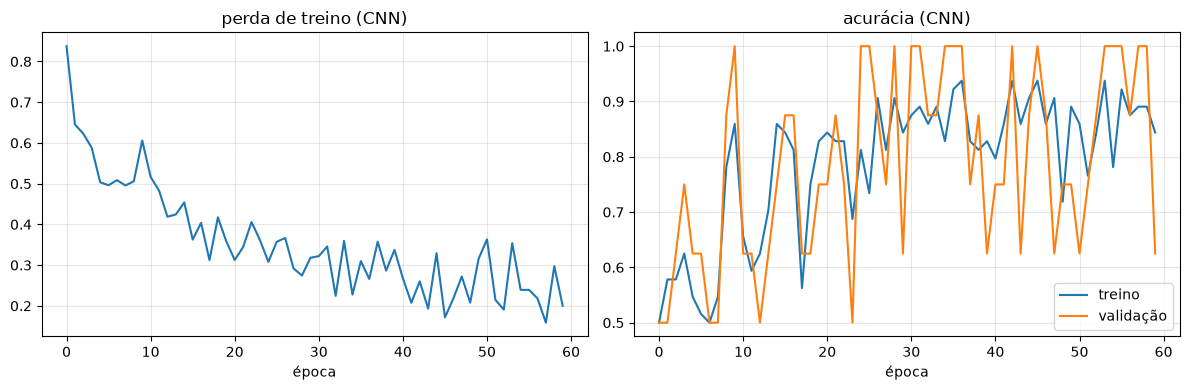

In [8]:
import random, numpy as np
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T

torch.manual_seed(0); random.seed(0); np.random.seed(0)
IMG = 128
norm = T.Normalize([0.5] * 3, [0.5] * 3)
tf_train = T.Compose([T.RandomResizedCrop(IMG, scale=(0.5, 1.0)), T.RandomHorizontalFlip(), T.RandomRotation(15),
                      T.ColorJitter(0.3, 0.3, 0.3), T.ToTensor(), norm])
tf_eval = T.Compose([T.Resize((IMG, IMG)), T.ToTensor(), norm])

class FolderByName(Dataset):
    def __init__(self, split, tf):
        self.files = sorted(glob.glob(os.path.join(DATASET, split, 'images', '*.jpg')))
        self.tf = tf
    def __len__(self):
        return len(self.files)
    def __getitem__(self, i):
        p = self.files[i]
        return self.tf(Image.open(p).convert('RGB')), CLASSES.index(true_cls(p))

dl_train = DataLoader(FolderByName('train', tf_train), batch_size=16, shuffle=True)
dl_val = DataLoader(FolderByName('val', tf_eval), batch_size=16)
dl_test = DataLoader(FolderByName('test', tf_eval), batch_size=16)

def block(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))

class SmallCNN(nn.Module):
    def __init__(self, n):
        super().__init__()
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(self, x):
        return self.head(self.features(x))

def accuracy(model, dl):
    model.eval(); ok = n = 0
    with torch.no_grad():
        for x, y in dl:
            ok += (model(x.to(TORCH_DEVICE)).argmax(1).cpu() == y).sum().item(); n += len(y)
    return ok / n

cnn = SmallCNN(len(CLASSES)).to(TORCH_DEVICE)
opt = torch.optim.Adam(cnn.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()
hist, best_val, best_state = [], -1, None
t0 = time.perf_counter()
for epoch in range(60):
    cnn.train(); tot = 0
    for x, y in dl_train:
        x, y = x.to(TORCH_DEVICE), y.to(TORCH_DEVICE)
        opt.zero_grad(); loss = loss_fn(cnn(x), y); loss.backward(); opt.step(); tot += loss.item() * len(y)
    tr_acc, va_acc = accuracy(cnn, dl_train), accuracy(cnn, dl_val)
    hist.append((tot / len(dl_train.dataset), tr_acc, va_acc))
    if va_acc >= best_val:
        best_val, best_state = va_acc, {k: v.detach().clone() for k, v in cnn.state_dict().items()}
cnn_train_time = time.perf_counter() - t0
cnn.load_state_dict(best_state)
acc_cnn = accuracy(cnn, dl_test)
print(f'tempo de treino: {cnn_train_time/60:.1f} min | melhor acc val: {best_val:.0%} | acc teste: {acc_cnn:.0%}')

h = np.array(hist)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h[:, 0]); ax[0].set_title('perda de treino (CNN)'); ax[0].set_xlabel('época')
ax[1].plot(h[:, 1], label='treino'); ax[1].plot(h[:, 2], label='validação'); ax[1].set_title('acurácia (CNN)')
ax[1].set_xlabel('época'); ax[1].legend()
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.show()

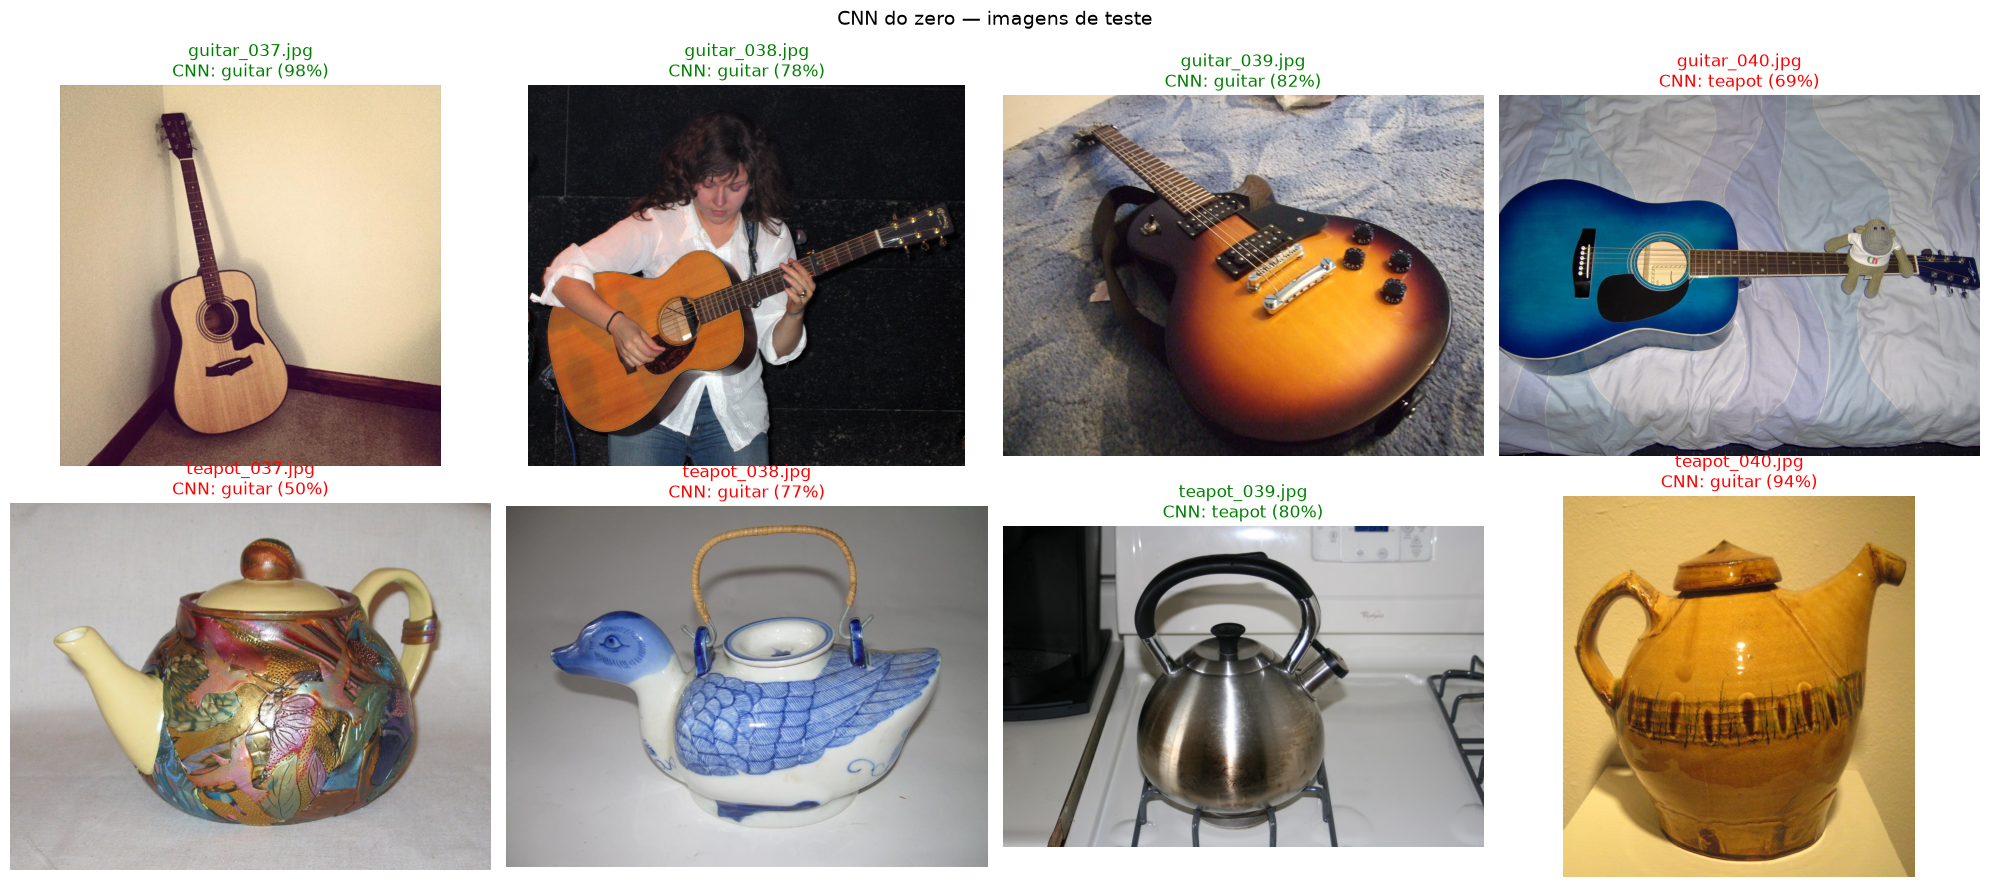

,imagem,classe real,predição,confiança,acerto
0,guitar_037.jpg,guitar,guitar,0.980,True
1,guitar_038.jpg,guitar,guitar,0.779,True
2,guitar_039.jpg,guitar,guitar,0.822,True
3,guitar_040.jpg,guitar,teapot,0.691,False
4,teapot_037.jpg,teapot,guitar,0.504,False
5,teapot_038.jpg,teapot,guitar,0.772,False
6,teapot_039.jpg,teapot,teapot,0.798,True
7,teapot_040.jpg,teapot,guitar,0.940,False


In [9]:
cnn.eval()
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
cnn_rows = []
with torch.no_grad():
    for ax, p in zip(axes.flat, TEST_IMGS):
        img = Image.open(p).convert('RGB')
        prob = torch.softmax(cnn(tf_eval(img)[None].to(TORCH_DEVICE)), 1)[0].cpu()
        pred = CLASSES[int(prob.argmax())]
        cnn_rows.append({'imagem': os.path.basename(p), 'classe real': true_cls(p), 'predição': pred,
                         'confiança': round(float(prob.max()), 3), 'acerto': pred == true_cls(p)})
        ax.imshow(img); ax.axis('off')
        ax.set_title(f'{os.path.basename(p)}\nCNN: {pred} ({prob.max():.0%})', color='green' if pred == true_cls(p) else 'red')
fig.suptitle('CNN do zero — imagens de teste', fontsize=14); plt.tight_layout(); plt.show()
pd.DataFrame(cnn_rows)

## f) Comparação final das 3 abordagens

**Tempo de inferência:** média por imagem em 3 passadas sobre as 8 imagens de teste, no mesmo dispositivo, depois de uma passada completa de aquecimento (*warm-up*). Sem o aquecimento completo, o primeiro modelo medido pagava a compilação de kernels da GPU e parecia ~6x mais lento. O tempo inclui o pré-processamento de cada abordagem.
A métrica de "precisão" comparável entre as três é o **acerto por imagem no teste**. Para o YOLO customizado também vale o mAP50 de validação, calculado acima.

In [10]:
def sync():
    if DEVICE == 'mps': torch.mps.synchronize()
    if DEVICE == 0: torch.cuda.synchronize()

def time_per_image(fn, imgs, passes=3):
    for p in imgs:  # aquecimento: uma passada completa (cada tamanho de imagem compila kernels na 1ª vez)
        fn(p)
    sync(); t0 = time.perf_counter()
    for _ in range(passes):
        for p in imgs:
            fn(p)
    sync()
    return (time.perf_counter() - t0) / (passes * len(imgs)) * 1000

def cnn_predict(p):
    with torch.no_grad():
        return cnn(tf_eval(Image.open(p).convert('RGB'))[None].to(TORCH_DEVICE)).argmax(1).item()

inf_ms = {
    'custom': time_per_image(lambda p: custom.predict(p, device=DEVICE, verbose=False), TEST_IMGS),
    'coco': time_per_image(lambda p: coco.predict(p, device=DEVICE, verbose=False), TEST_IMGS),
    'cnn': time_per_image(cnn_predict, TEST_IMGS),
}
best_ep = max((30, 60), key=lambda e: yolo_cmp.loc[e, 'mAP50-95'])
final = pd.DataFrame([
    {'abordagem': 'YOLO customizado (YOLO11n fine-tuned, 60 ép.)',
     'facilidade de uso': 'Média — exige rotular caixas (Make Sense) e montar data.yaml; treino é 1 linha',
     'acerto no teste': f'{acc_custom:.0%}',
     'mAP50 val': f"{yolo_cmp.loc[60, 'mAP50']:.3f}",
     'tempo de treino': f'{train_time[60]/60:.1f} min (30 ép.: {train_time[30]/60:.1f} min)',
     'inferência (ms/img)': round(inf_ms['custom'], 1)},
    {'abordagem': 'YOLO padrão (COCO, sem treino)',
     'facilidade de uso': 'Alta — zero dado e zero treino, mas só conhece as 80 classes do COCO',
     'acerto no teste': f'{acc_coco:.0%}',
     'mAP50 val': 'n/a (classes inexistentes)',
     'tempo de treino': '0',
     'inferência (ms/img)': round(inf_ms['coco'], 1)},
    {'abordagem': 'CNN do zero (PyTorch)',
     'facilidade de uso': 'Média/baixa — rótulo só por pasta/nome, mas arquitetura, augmentation e loop de treino são manuais',
     'acerto no teste': f'{acc_cnn:.0%}',
     'mAP50 val': 'n/a (só classifica, não localiza)',
     'tempo de treino': f'{cnn_train_time/60:.1f} min',
     'inferência (ms/img)': round(inf_ms['cnn'], 1)},
]).set_index('abordagem')
print('Device:', DEVICE, '| melhor YOLO por mAP50-95 na validação:', best_ep, 'épocas')
final

Device: mps | melhor YOLO por mAP50-95 na validação: 30 épocas


,facilidade de uso,acerto no teste,mAP50 val,tempo de treino,inferência (ms/img)
abordagem,,,,,
"YOLO customizado (YOLO11n fine-tuned, 60 ép.)",Média — exige rotular caixas (Make Sense) e mo...,75%,0.847,2.9 min (30 ép.: 1.4 min),11.0
"YOLO padrão (COCO, sem treino)","Alta — zero dado e zero treino, mas só conhece...",0%,n/a (classes inexistentes),0,9.1
CNN do zero (PyTorch),"Média/baixa — rótulo só por pasta/nome, mas ar...",50%,"n/a (só classifica, não localiza)",0.4 min,4.2


### Conclusão crítica

**Resultados (execução local, Apple M4 Max / `mps`):**

| | YOLO custom 30 ép. | YOLO custom 60 ép. | YOLO padrão (COCO) | CNN do zero |
|---|---|---|---|---|
| Precisão (val) | 0,902 | 0,636 | — | — |
| Recall (val) | 0,690 | 0,861 | — | — |
| mAP50 (val) | 0,779 | 0,847 | — | — |
| mAP50-95 (val) | 0,574 | 0,488 | — | — |
| Acerto por imagem (teste, 8 imgs) | — | 75% (6/8) | 0% (0/8) | 50% (4/8) |
| Tempo de treino | 1,4 min | 2,9 min | 0 | 0,4 min |
| Inferência | — | 11,0 ms/img | 9,1 ms/img | 4,2 ms/img |

1. **YOLO customizado é a única abordagem que resolve o problema.** Ele localiza *e* classifica, acertou todos os violões do teste e errou 2 dos 4 bules, confundidos com violão. O custo é o trabalho de rotulagem: desenhar caixas e manter a ordem das classes igual no Make Sense e no `data.yaml`. O treino em si é uma linha de código e leva poucos minutos.
2. **30 vs 60 épocas: não dá para declarar vencedor.** Com 60 épocas a perda de treino caiu mais e o mAP50 e o recall subiram, mas a precisão e o mAP50-95 caíram. Além disso, numa execução anterior idêntica, o modelo de 60 épocas teve precisão 0,93 e mAP50-95 0,56. O treino em GPU não é determinístico, e com só 8 imagens de validação cada imagem vale 12,5 pontos percentuais. A diferença entre 30 e 60 épocas está dentro dessa variação de uma execução para outra. A perda de validação de caixa subiu de 30 para 60 épocas (1,34 → 1,61), sinal inicial de *overfitting*. A conclusão honesta é que, neste volume de dados, ~30 épocas bastam. Ganhar qualidade de verdade exige **mais imagens**, não mais épocas.
3. **O YOLO padrão (COCO) erra tudo, e isso é esperado.** O COCO não tem `guitar` nem `teapot`. O modelo "vê" a pessoa que toca, ou chama o violão de `toothbrush`, `tennis racket` ou `bed` e o bule de `vase`, `bowl` ou `oven`. É a opção mais fácil (zero dado, zero treino), mas só serve quando o objeto já é uma das 80 classes do COCO. O contraste mostra o valor do *transfer learning*: o mesmo YOLO11n foi de 0% para 75% com 64 imagens rotuladas e ~3 minutos de treino.
4. **A CNN do zero é a mais rápida, mas não generaliza.** Ela chegou a 100% na validação (8 imagens) e caiu para 50% no teste, o mesmo que chutar. Sem pesos pré-treinados, 64 imagens não bastam para aprender formas, e ela memoriza fundo e cor. Os 100% na validação foram sorte num conjunto minúsculo, porque guardamos a época que melhor acertou essas 8 imagens. A CNN é ~2,5x mais rápida na inferência e não precisa de caixas, mas só classifica a imagem inteira, sem localizar o objeto.
5. **Limitações:** teste com 8 imagens (intervalos de confiança enormes), imagens de terceiros (Open Images) e teste sem caixas rotuladas, o que impede calcular mAP no teste. Próximos passos: 200+ imagens por classe, rotular o teste, *k-fold* ou várias sementes para medir a variância, e uma CNN com *transfer learning* (ex.: MobileNet) como comparação mais justa com o YOLO.

**Recomendação:** para detectar objetos fora do COCO, **YOLO com fine-tuning** é o caminho, e o investimento que mais rende é rotular mais dados, não treinar por mais épocas.